# Лабораторная работа №2. Исследовательский анализ данных
**Выполнил:** Курбатов М. П., группа 4417.  
**Вариант:** 13.  
**Цель:** изучить взаимосвязи между признаками набора данных о фильмах и представить результаты с помощью графиков.

Набор `movies.csv` содержит название фильма, год выхода, рейтинг, количество голосов, длительность, основной жанр и страну производства. Для выполнения загрузите файл в Colab и укажите его путь в первой ячейке.

## 1. Загрузка, обзор и предварительная обработка данных
Сначала проверяю размер таблицы, типы столбцов, описательную статистику, пропуски и дубликаты. Исходный файл читается один раз.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/movies.csv'  # Укажите путь к своему CSV.
df = pd.read_csv(file_path, sep=';')
initial_rows = len(df)
df.head()  # первые строки

,title,release_year,score,number_of_votes,duration,main_genre,main_production
0,David Attenborough: A Life on Our Planet,2020.0,9.0,31180.0,83,documentary,GB
1,Inception,2010.0,8.8,2268288.0,148,scifi,GB
2,Forrest Gump,1994.0,8.8,1994599.0,142,drama,US
3,Anbe Sivam,2003.0,8.7,20595.0,160,comedy,IN
4,Bo Burnham: Inside,2021.0,8.7,44074.0,87,comedy,US


In [2]:
df.info()  # информация о датасете

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 389 entries, 0 to 388
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   title            384 non-null    object 
 1   release_year     387 non-null    float64
 2   score            386 non-null    float64
 3   number_of_votes  388 non-null    float64
 4   duration         389 non-null    int64  
 5   main_genre       389 non-null    object 
 6   main_production  388 non-null    object 
dtypes: float64(3), int64(1), object(3)
memory usage: 21.4+ KB


In [3]:
df.describe()  # описательная статистика

,release_year,score,number_of_votes,duration
count,387.000000,386.000000,3.880000e+02,389.000000
mean,2010.976744,7.512176,1.391523e+05,123.352185
std,10.805726,0.443870,2.365279e+05,28.304800
min,1954.000000,6.900000,1.013900e+04,28.000000
25%,2007.500000,7.100000,2.055375e+04,104.000000
50%,2014.000000,7.400000,4.606950e+04,122.000000
75%,2018.000000,7.800000,1.551585e+05,139.000000
max,2022.000000,9.000000,2.268288e+06,229.000000


In [4]:
print('Пропуски до обработки:')
print(df.isna().sum())

print('\nДубликаты до обработки:', df.duplicated().sum())

missing_rows = df.isna().any(axis=1).sum()
df = df.dropna().copy()  # удаляем пропуски
df = df.drop_duplicates().copy()  # удаляем дубликаты

df['main_genre'] = df['main_genre'].str.strip().str.lower()  # жанры
df['main_genre'] = df['main_genre'].replace('dramaa', 'drama')  # исправляем опечатку
df['main_production'] = df['main_production'].str.strip().str.upper()  # страны
df['release_year'] = df['release_year'].astype(int)  # год в int
df['number_of_votes'] = df['number_of_votes'].astype(int)  # голоса в int
print('\nРазмер после обработки:', df.shape)
removed_rows = initial_rows - len(df)
print('\nПропуски после обработки:')
print(df.isna().sum())
print('\nДубликаты после обработки:', df.duplicated().sum())

Пропуски до обработки:
title              5
release_year       2
score              3
number_of_votes    1
duration           0
main_genre         0
main_production    1
dtype: int64

Дубликаты до обработки: 2

Размер после обработки: (381, 7)

Пропуски после обработки:
title              0
release_year       0
score              0
number_of_votes    0
duration           0
main_genre         0
main_production    0
dtype: int64

Дубликаты после обработки: 0


Строки с пропусками удалены, поскольку для исследования используются все основные признаки; повторные записи также удалены. Жанры приведены к единому регистру, исправлена опечатка, коды стран нормализованы. Год и число голосов преобразованы в целые числа. Следующая ячейка показывает статистику **после** очистки: её использую для выводов и всех дальнейших графиков.

In [5]:
df.info()
display(df.describe())
print('Уникальных жанров:', df['main_genre'].nunique())
print('Строк до обработки:', initial_rows)
print('Строк с пропусками:', missing_rows)
print('Строк после обработки:', len(df))
assert df.isna().sum().sum() == 0
assert df.duplicated().sum() == 0

<class 'pandas.core.frame.DataFrame'>
Index: 381 entries, 0 to 386
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   title            381 non-null    object 
 1   release_year     381 non-null    int64  
 2   score            381 non-null    float64
 3   number_of_votes  381 non-null    int64  
 4   duration         381 non-null    int64  
 5   main_genre       381 non-null    object 
 6   main_production  381 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 23.8+ KB
Уникальных жанров: 15
Строк до обработки: 389
Строк с пропусками: 6
Строк после обработки: 381


,release_year,score,number_of_votes,duration
count,381.000000,381.000000,3.810000e+02,381.000000
mean,2010.997375,7.509186,1.362626e+05,123.530184
std,10.862659,0.445084,2.350996e+05,28.528329
min,1954.000000,6.900000,1.013900e+04,28.000000
25%,2008.000000,7.100000,2.043000e+04,104.000000
50%,2014.000000,7.400000,4.491700e+04,122.000000
75%,2018.000000,7.800000,1.534630e+05,139.000000
max,2022.000000,9.000000,2.268288e+06,229.000000


## 2. Матрица диаграмм рассеяния и график по категориям
Рассматриваю все четыре числовых признака. На диагонали матрицы находятся гистограммы, вне диагонали — парные диаграммы рассеяния.

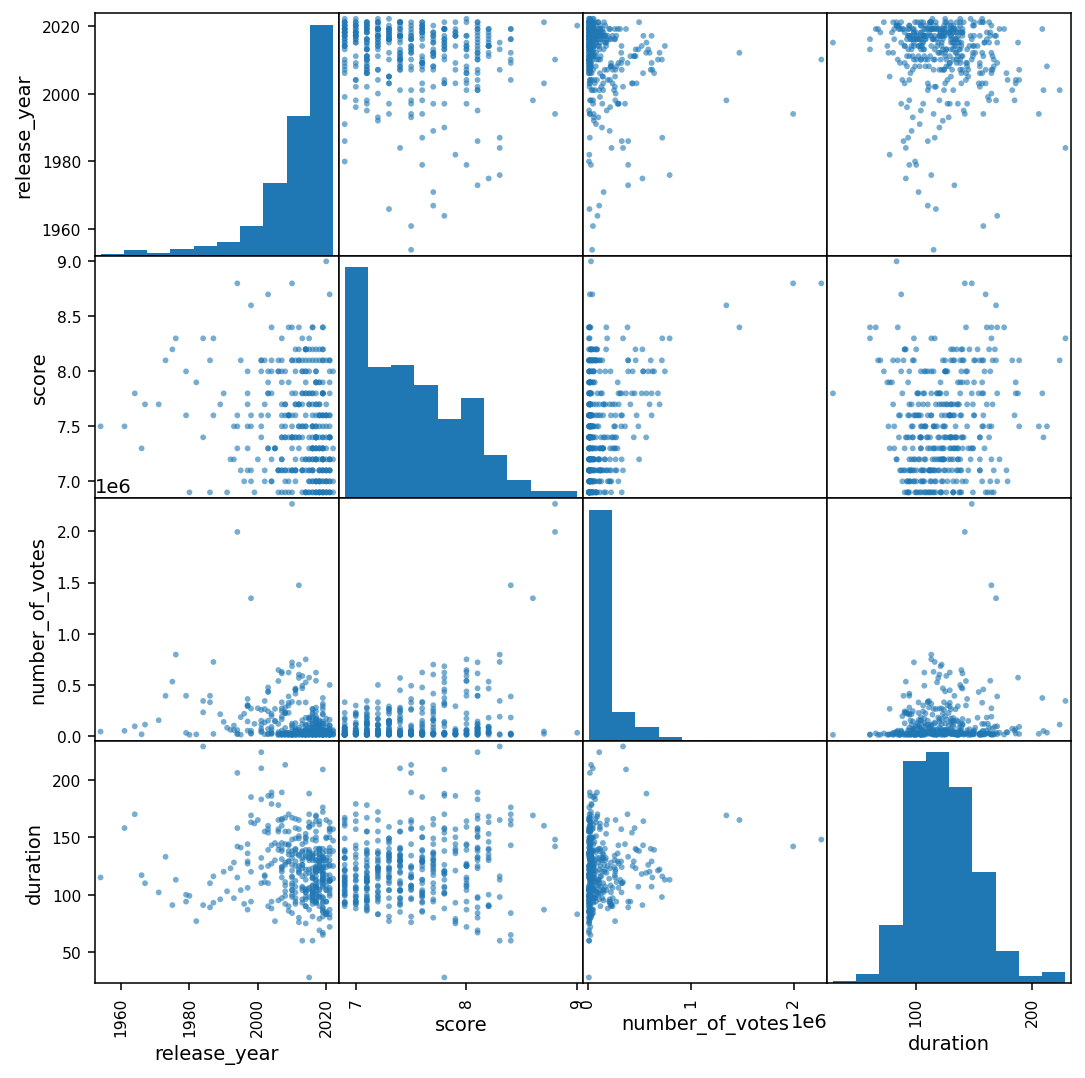

In [6]:
num_cols = ['release_year', 'score', 'number_of_votes', 'duration']

pd.plotting.scatter_matrix(
    df[num_cols],
    figsize=(9, 9),
    diagonal='hist',
    alpha=0.6
)

plt.show()

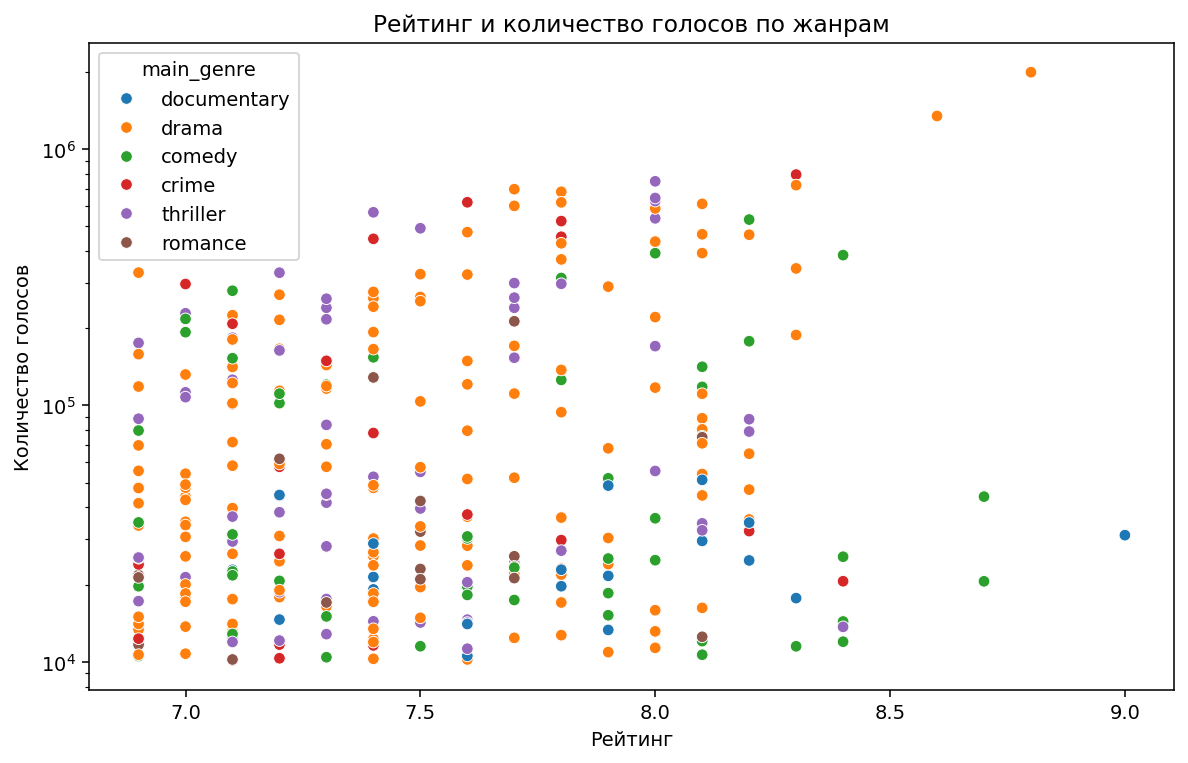

In [7]:
genres = df['main_genre'].value_counts().head(6).index  # популярные жанры

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df[df['main_genre'].isin(genres)],
    x='score',
    y='number_of_votes',
    hue='main_genre'
)

plt.yscale('log')  # удобнее видеть голоса
plt.title('Рейтинг и количество голосов по жанрам')
plt.xlabel('Рейтинг')
plt.ylabel('Количество голосов')
plt.show()

На графике по жанрам использованы шесть наиболее представленных категорий. Логарифмическая шкала количества голосов помогает увидеть как обычные, так и очень популярные фильмы. Перекрытие групп означает, что жанр не даёт чёткого разделения фильмов по рейтингу и числу голосов. Силу линейных связей дополнительно оцениваю через корреляции в разделе 4.

## 3. Гистограммы числовых признаков
Для каждого числового столбца строю гистограмму. Выбрано 15 интервалов: такая детализация позволяет увидеть форму распределений без большого числа почти пустых столбцов.

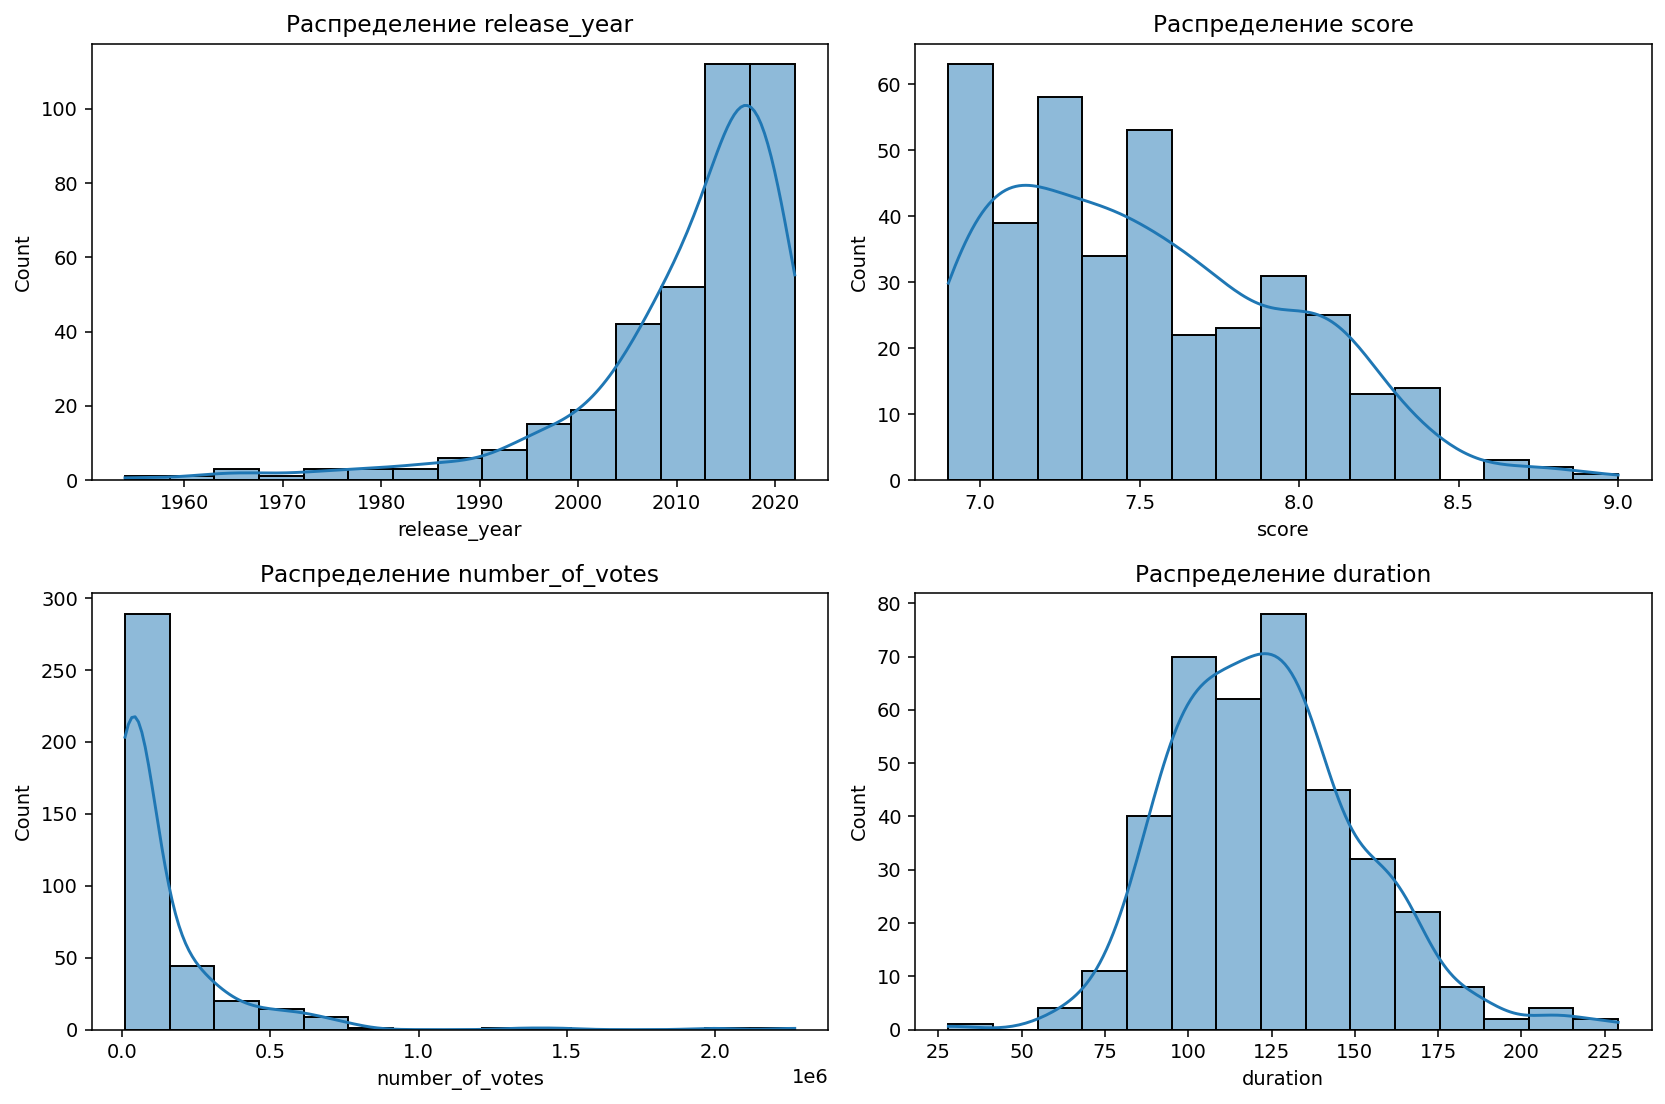

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, num_cols):
    sns.histplot(df[column], bins=15, kde=True, ax=ax)
    ax.set_title(f'Распределение {column}')

plt.tight_layout()
plt.show()

In [9]:
display(df[num_cols].agg(['mean', 'median', 'min', 'max']))

,release_year,score,number_of_votes,duration
mean,2010.997375,7.509186,1.362626e+05,123.530184
median,2014.000000,7.400000,4.491700e+04,122.000000
min,1954.000000,6.900000,1.013900e+04,28.000000
max,2022.000000,9.000000,2.268288e+06,229.000000


Распределения сравниваю по центру, разбросу и асимметрии. При правосторонней асимметрии редкие большие значения могут заметно увеличивать среднее относительно медианы. Численные характеристики очищенной выборки приведены в таблице выше.

Для очищенных данных среднее число голосов равно 136262.61, медиана — 44917. Медиана рейтинга — 7.4, длительности — 122 минуты.

## 4. Корреляция, ковариация и тепловая карта
Корреляция Пирсона показывает силу и направление линейной связи. Ковариация зависит от масштаба признаков, поэтому её абсолютные значения между разными парами напрямую не сравниваю.

,release_year,score,number_of_votes,duration
release_year,1.000000,-0.152453,-0.212222,-0.103095
score,-0.152453,1.000000,0.347352,0.127034
number_of_votes,-0.212222,0.347352,1.000000,0.102842
duration,-0.103095,0.127034,0.102842,1.000000


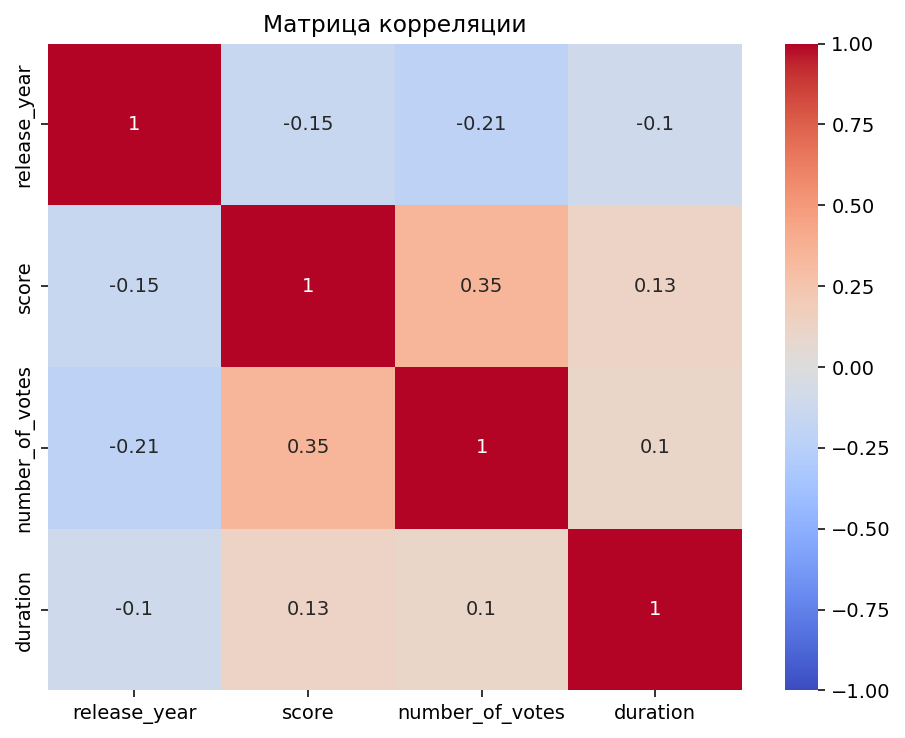

In [10]:
corr = df[num_cols].corr()  # корреляция

display(corr)

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Матрица корреляции')
plt.show()

In [11]:
cov = df[num_cols].cov()  # ковариация
display(cov)

,release_year,score,number_of_votes,duration
release_year,117.997362,-0.737081,-5.419733e+05,-31.948605
score,-0.737081,0.198100,3.634659e+04,1.613011
number_of_votes,-541973.324720,36346.593100,5.527182e+10,689760.859283
duration,-31.948605,1.613011,6.897609e+05,813.865534


In [12]:
print('Рейтинг и количество голосов:', round(corr.loc['score', 'number_of_votes'], 3))
print('Год выхода и количество голосов:', round(corr.loc['release_year', 'number_of_votes'], 3))
print('Длительность и рейтинг:', round(corr.loc['duration', 'score'], 3))

Рейтинг и количество голосов: 0.347
Год выхода и количество голосов: -0.212
Длительность и рейтинг: 0.127


Знак коэффициента показывает направление линейной связи. Значения, близкие к нулю, означают слабую линейную связь, но не исключают нелинейную. Корреляция не доказывает причинность.

## 5. Задания варианта 13
### 5.1. Seaborn: количество фильмов по странам и жанрам с 2020 года
Отбираю фильмы с годом выхода не меньше 2020. Число фильмов каждой категории подсчитывает `countplot`. Используется очищенный `df`, без повторного чтения файла.

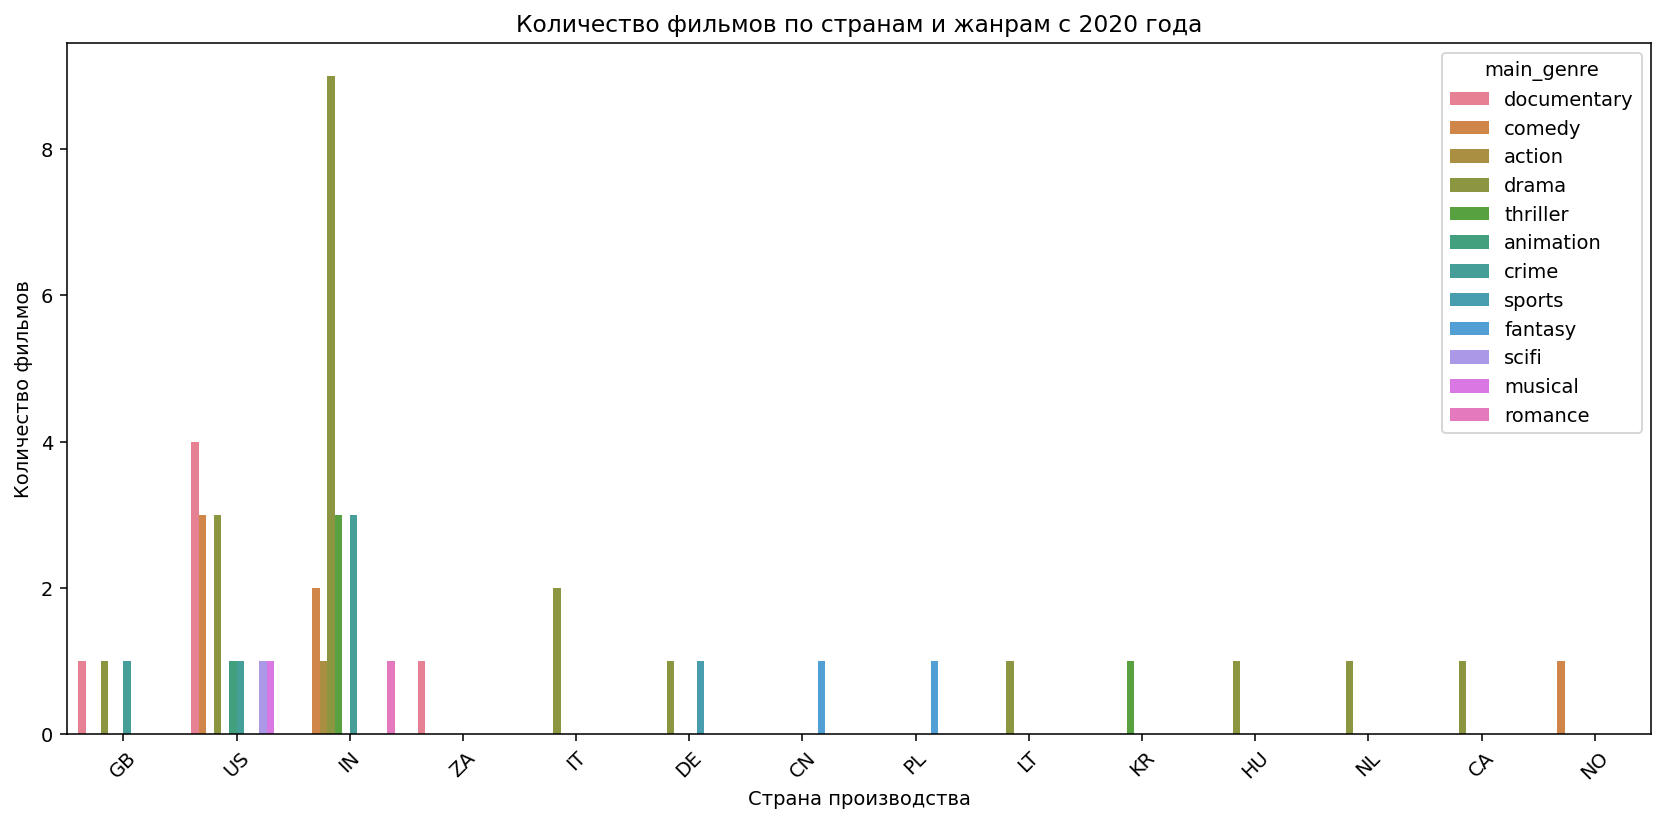

In [13]:
recent = df[df['release_year'] >= 2020]  # фильмы с 2020 года

plt.figure(figsize=(12, 6))

sns.countplot(
    data=recent,
    x='main_production',
    hue='main_genre'
)

plt.title('Количество фильмов по странам и жанрам с 2020 года')
plt.xlabel('Страна производства')
plt.ylabel('Количество фильмов')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
print('Количество фильмов с 2020 года:', len(recent))
display(recent.groupby(['main_production', 'main_genre']).size().sort_values(ascending=False).head(10).to_frame('Количество фильмов'))

Количество фильмов с 2020 года: 49


Количество фильмов
main_production main_genre                     
IN              drama                         9
US              documentary                   4
IN              thriller                      3
                crime                         3
US              drama                         3
                comedy                        3
IN              comedy                        2
IT              drama                         2
DE              sports                        1
                drama                         1

Диаграмма показывает представленные сочетания страны и жанра. Таблица выше позволяет проверить наиболее многочисленные группы и сформулировать вывод без оценки высоты столбцов на глаз.

После фильтрации осталось 49 фильмов. Максимальная группа — IN/drama: 9 фильмов.

### 5.2. Pandas plot: среднее количество голосов по годам после 2010 года
Использую `pivot_table` и `plot`. По условию оставлены только синие ромбовидные маркеры размера 14, без соединяющей линии.

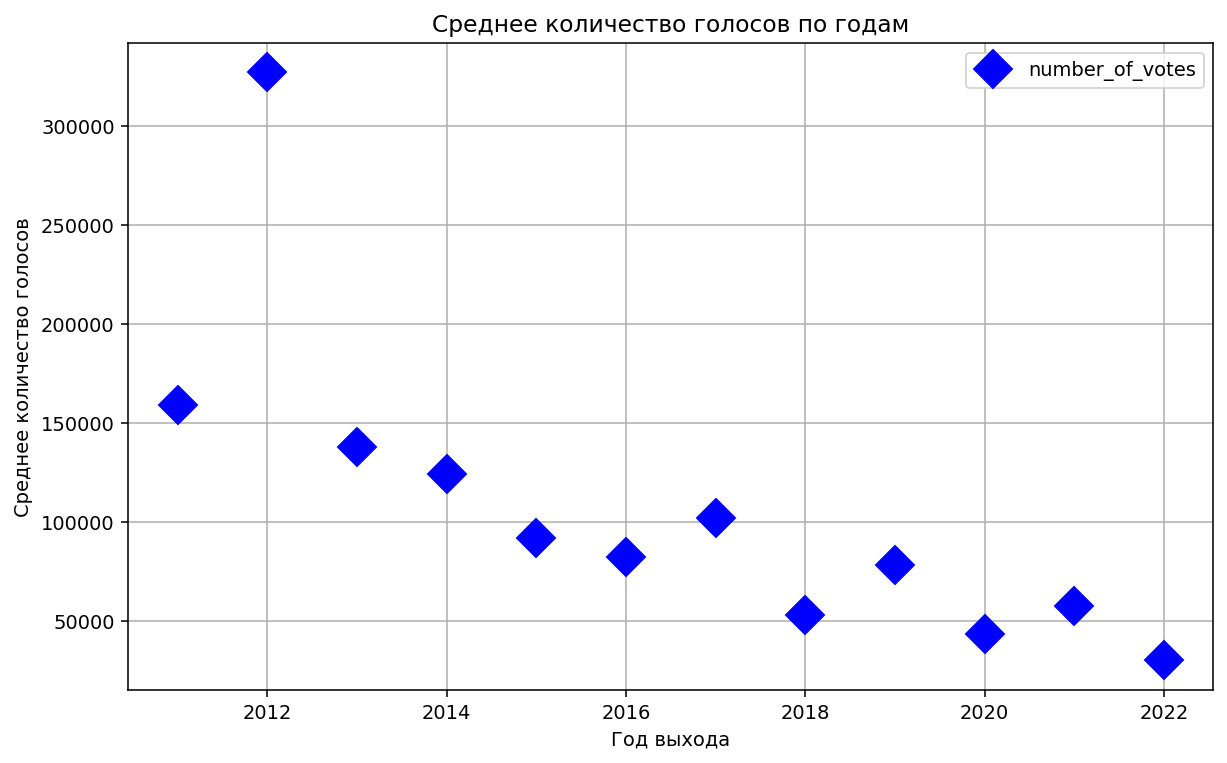

In [15]:
votes_by_year = df[df['release_year'] > 2010].pivot_table(
    index='release_year',
    values='number_of_votes',
    aggfunc='mean'
)

votes_by_year.plot(
    marker='D',        # ромб
    linestyle='None',  # без линии
    color='blue',
    markersize=14,
    figsize=(10, 6)
)

plt.title('Среднее количество голосов по годам')
plt.xlabel('Год выхода')
plt.ylabel('Среднее количество голосов')
plt.grid(True)
plt.show()

In [16]:
display(votes_by_year)
print('Максимум среднего числа голосов, год:', votes_by_year['number_of_votes'].idxmax())
print('Минимум среднего числа голосов, год:', votes_by_year['number_of_votes'].idxmin())

Максимум среднего числа голосов, год: 2012
Минимум среднего числа голосов, год: 2022


,number_of_votes
release_year,
2011,159163.285714
2012,327210.333333
2013,137732.066667
2014,124290.684211
2015,91954.000000
2016,82609.076923
2017,101859.176471
2018,53095.884615
2019,78380.162162


Различия средних показывают неодинаковую популярность фильмов разных лет в этом наборе. Более низкие значения у новых фильмов могут быть связаны с меньшим временем накопления голосов, но график сам по себе эту причину не доказывает.

### 5.3. Matplotlib: доли фильмов с 2020 года по годам
Круговая диаграмма строится по тому же очищенному поднабору `recent`.

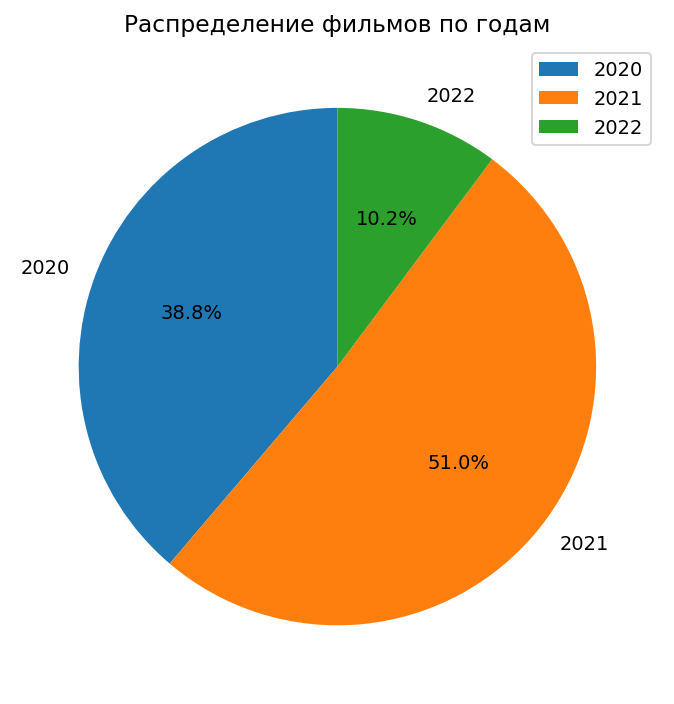

In [17]:
year_counts = recent['release_year'].value_counts().sort_index()

plt.figure(figsize=(10, 6))

plt.pie(
    year_counts.values,
    labels=year_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Распределение фильмов по годам')
plt.legend(year_counts.index, bbox_to_anchor=(1, 1))
plt.show()

In [18]:
display(pd.DataFrame({'Количество': year_counts, 'Доля, %': (year_counts / year_counts.sum() * 100).round(1)}))

,Количество,"Доля, %"
release_year,,
2020,19,38.8
2021,25,51.0
2022,5,10.2


Самый большой сектор соответствует году с максимальным количеством фильмов в подвыборке. Точные количества и доли приведены в таблице выше.

## 6. Hexagonal binning plot
Каждая шестиугольная ячейка показывает число наблюдений в соответствующем диапазоне длительности и рейтинга.

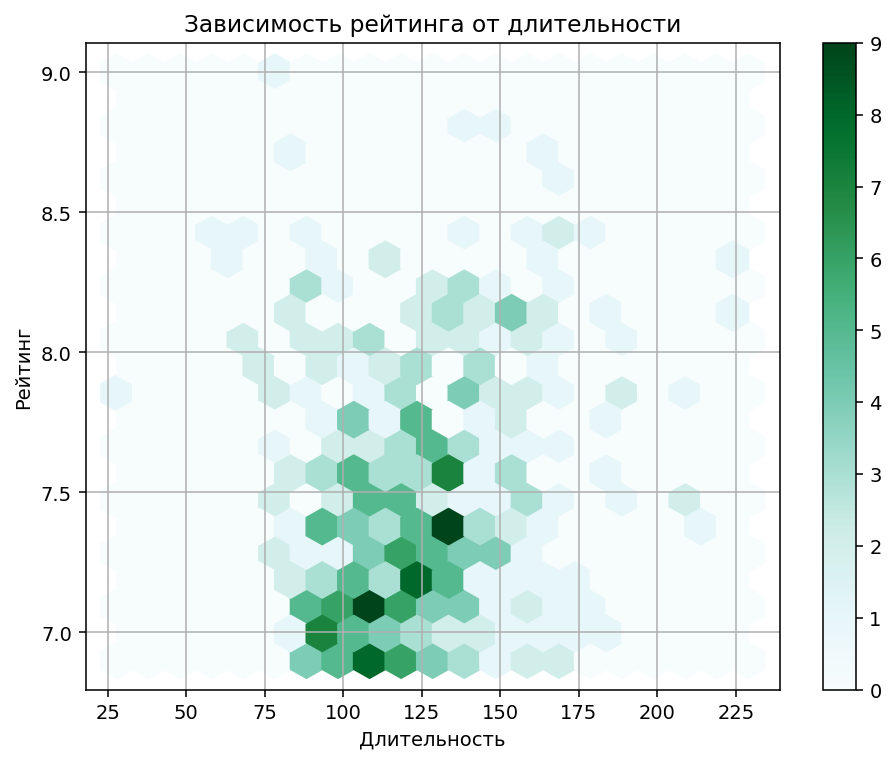

In [19]:
df.plot(
    x='duration',
    y='score',
    kind='hexbin',
    gridsize=20,
    figsize=(8, 6),
    grid=True
)

plt.title('Зависимость рейтинга от длительности')
plt.xlabel('Длительность')
plt.ylabel('Рейтинг')
plt.show()

Более тёмные ячейки показывают области наибольшей плотности наблюдений. О наличии линейной связи сужу вместе с коэффициентом корреляции длительности и рейтинга из раздела 4.

## 7. Boxplot количества голосов
Проверяю распределение голосов и границы по правилу 1,5 IQR. Значения за границами не удаляются автоматически: популярный фильм с большим числом голосов не обязательно является ошибкой.

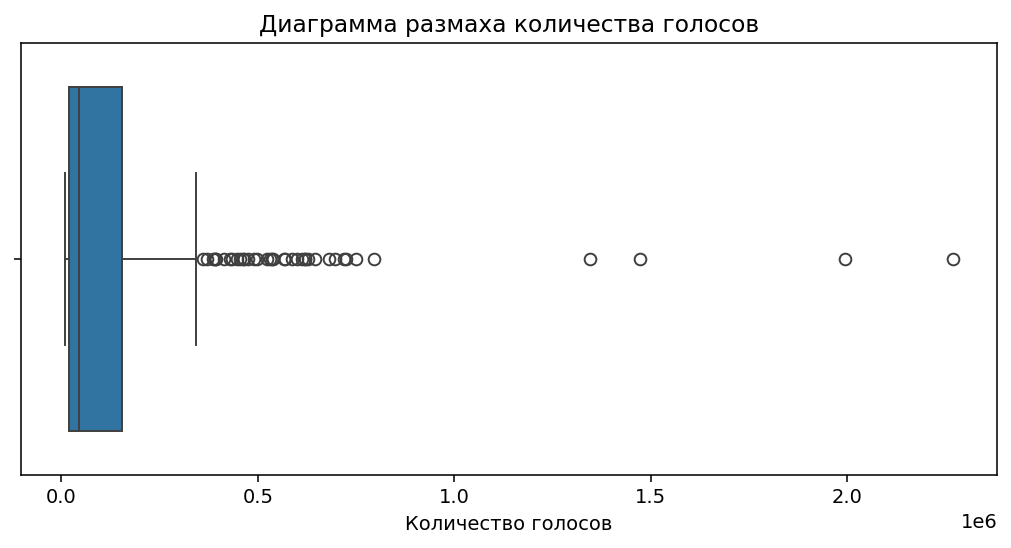

In [20]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df['number_of_votes']
)

plt.title('Диаграмма размаха количества голосов')
plt.xlabel('Количество голосов')
plt.show()

In [21]:
q1, q3 = df['number_of_votes'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
upper_whisker = df.loc[df['number_of_votes'] <= upper_fence, 'number_of_votes'].max()
print('Верхняя граница по правилу 1,5 IQR:', upper_fence)
print('Фактический конец верхнего уса:', upper_whisker)
print('Наблюдений выше границы:', (df['number_of_votes'] > upper_fence).sum())

Верхняя граница по правилу 1,5 IQR: 353012.5
Фактический конец верхнего уса: 342335
Наблюдений выше границы: 39


Граница Q3 + 1,5·IQR и фактический конец верхнего уса могут различаться: ус заканчивается на максимальном наблюдении внутри границы. Отдельные точки показывают фильмы с необычно большим количеством голосов.

## 8. Категория по числовому признаку
По рейтингу создаю три уровня: до 7,2 включительно, выше 7,2 до 7,7 включительно и выше 7,7. Boxplot строится по исходному рейтингу для каждой новой категории.

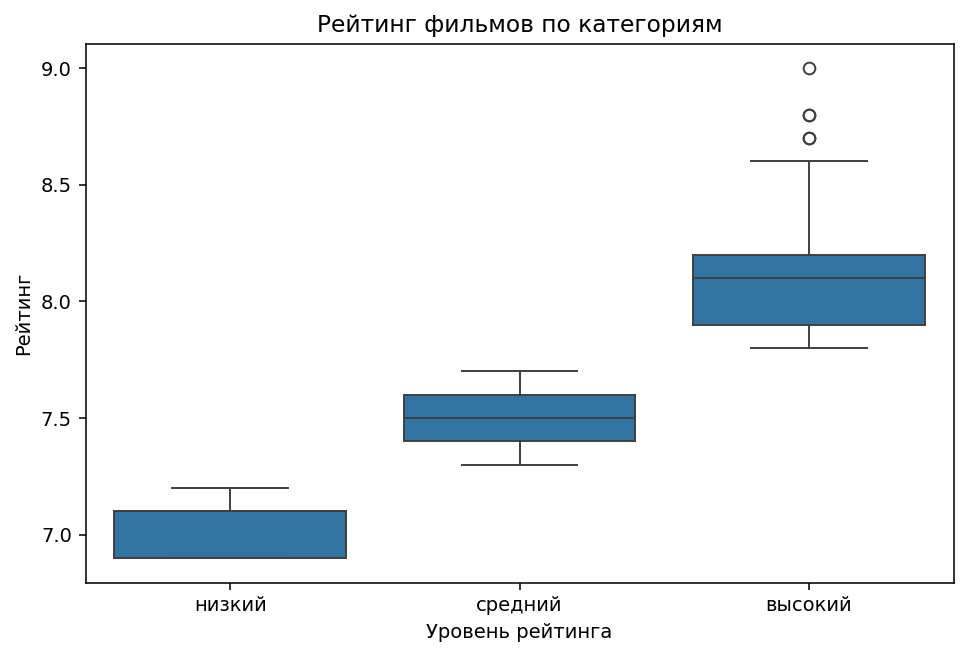

In [22]:
df['score_level'] = pd.cut(
    df['score'],
    bins=[0, 7.2, 7.7, 10],
    labels=['низкий', 'средний', 'высокий']
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='score_level',
    y='score'
)

plt.title('Рейтинг фильмов по категориям')
plt.xlabel('Уровень рейтинга')
plt.ylabel('Рейтинг')
plt.show()

In [23]:
display(df.groupby('score_level', observed=False)['score'].agg(['count', 'median', 'min', 'max']))

,count,median,min,max
score_level,,,,
низкий,132,7.1,6.9,7.2
средний,137,7.5,7.3,7.7
высокий,112,8.1,7.8,9.0


Разделение рейтингов между уровнями задано самими границами `pd.cut`, поэтому не является независимой найденной закономерностью. Численность групп и их медианы проверяю по таблице.

## 9. Ещё два boxplot по категориям
Первый график построен через Seaborn: рейтинг по восьми наиболее представленным жанрам. Второй — через Pandas: длительность по восьми наиболее представленным странам. Таким образом, использованы две библиотеки.

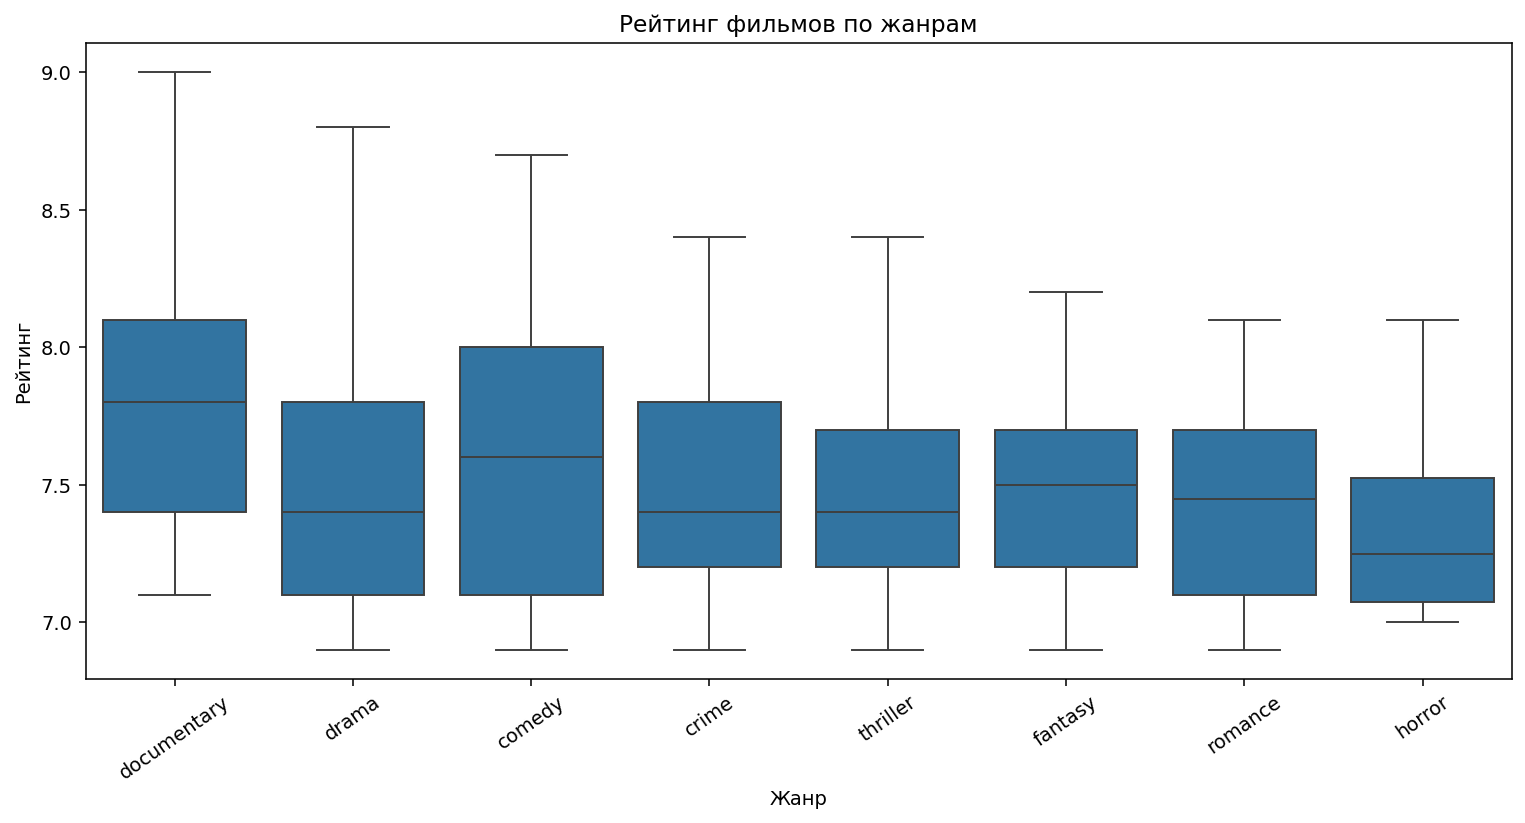

In [24]:
top_genres = df['main_genre'].value_counts().head(8).index

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df[df['main_genre'].isin(top_genres)],
    x='main_genre',
    y='score'
)

plt.title('Рейтинг фильмов по жанрам')
plt.xlabel('Жанр')
plt.ylabel('Рейтинг')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

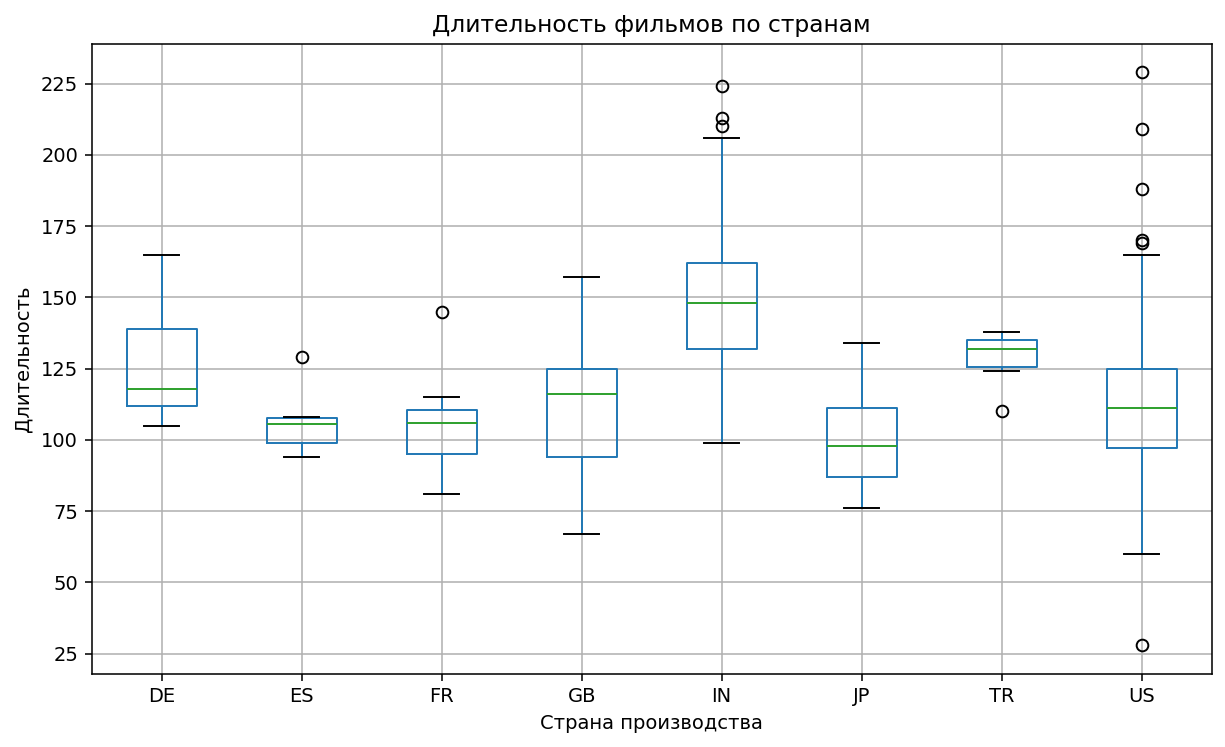

In [25]:
top_countries = df['main_production'].value_counts().head(8).index

df[df['main_production'].isin(top_countries)].boxplot(
    column='duration',
    by='main_production',
    figsize=(10, 6)
)

plt.suptitle('')
plt.title('Длительность фильмов по странам')
plt.xlabel('Страна производства')
plt.ylabel('Длительность')
plt.show()

In [26]:
display(df[df['main_genre'].isin(top_genres)].groupby('main_genre')['score'].agg(['count', 'median']))
display(df[df['main_production'].isin(top_countries)].groupby('main_production')['duration'].agg(['count', 'median']))

,count,median
main_genre,,
comedy,57,7.60
crime,21,7.40
documentary,20,7.80
drama,148,7.40
fantasy,19,7.50
horror,8,7.25
romance,20,7.45
thriller,59,7.40


,count,median
main_production,,
DE,9,118.0
ES,6,105.5
FR,7,106.0
GB,29,116.0
IN,115,148.0
JP,9,98.0
TR,7,132.0
US,151,111.0


Медианы позволяют сравнить типичные значения по группам, а перекрытие ящиков — оценить, насколько группы различаются. Выводы относятся к выбранным наиболее многочисленным категориям, а не ко всем фильмам.

## 10. Общий вывод
В работе исследован набор данных о фильмах: исходно 389 строк и 7 столбцов. После удаления 6 строк с пропусками и повторных записей осталось 381 наблюдение. Жанры и коды стран приведены к единому написанию, год выхода и число голосов преобразованы в целые числа.

Сильных линейных связей между числовыми признаками не найдено. Наиболее заметна положительная связь рейтинга с количеством голосов (r = 0.347). Среднее число голосов 136263 выше медианы 44917: распределение имеет длинный правый хвост. Высокие значения голосов не удалялись, поскольку популярность фильма сама по себе не является ошибкой.

С 2020 года в очищенной выборке 49 фильмов, распределение по годам: 2020 — 19, 2021 — 25, 2022 — 5. Наибольшее среднее число голосов после 2010 года приходится на 2012 год, наименьшее — на 2022. Различия могут зависеть от состава выборки и времени накопления голосов.

Матрица рассеяния, гистограммы, heatmap, hexbin и boxplot дополняют численные оценки. Сравнение жанров и стран показывает различия медиан при пересечении диапазонов. Выводы относятся к этому набору данных и не доказывают причинного влияния года, жанра или страны на рейтинг и популярность.